## Analyze training time vs. performance trade-offs by manually tracking runtime, memory consumption, and computational efficiency of different models, identifying optimal model complexity for real-world deployment.

In [8]:
import warnings; warnings.filterwarnings('ignore')
import time, tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

df = pd.read_csv('heart.csv')                          
X, y = df.drop(columns='target').values.astype(float), df['target'].values
print(X.shape)

(303, 13)


In [9]:
def auc(t, s):
    sp, sn = s[t == 1], s[t == 0]
    return (sp[:, None] > sn[None, :]).mean() + 0.5 * (sp[:, None] == sn[None, :]).mean()

def score(m, A): return m.predict_proba(A)[:, 1] if hasattr(m, 'predict_proba') else m.decision_function(A)     

In [10]:
models = {
    'LR':            lambda: LogisticRegression(max_iter=1000),
    'NB':            lambda: GaussianNB(),
    'kNN (k=15)':    lambda: KNeighborsClassifier(15),
    'Tree (depth 3)':lambda: DecisionTreeClassifier(max_depth=3, random_state=0),
    'Tree (full)':   lambda: DecisionTreeClassifier(random_state=0),
    'RF (10 trees)': lambda: RandomForestClassifier(10, random_state=0),
    'RF (50 trees)': lambda: RandomForestClassifier(50, random_state=0),
    'RF (200 trees)':lambda: RandomForestClassifier(200, random_state=0),
    'SVM (RBF)':     lambda: SVC(),
    'MLP (16)':      lambda: MLPClassifier((16,), max_iter=500, random_state=0),
    'MLP (64,64)':   lambda: MLPClassifier((64, 64), max_iter=500, random_state=0),
}
names = list(models)

In [11]:
def timed(fn):
    t0 = time.perf_counter(); out = fn(); return out, (time.perf_counter() - t0) * 1000       

def peak_mb(fn):                                     
    tracemalloc.start(); fn(); peak = tracemalloc.get_traced_memory()[1]; tracemalloc.stop(); return peak / 1e6

def model_bytes(o, seen=None):                        
    seen = seen if seen is not None else set()
    if id(o) in seen: return 0
    seen.add(id(o))
    if isinstance(o, np.ndarray): return o.nbytes
    if isinstance(o, (list, tuple)): return sum(model_bytes(i, seen) for i in o)
    if isinstance(o, dict): return sum(model_bytes(i, seen) for i in o.values())
    if hasattr(o, 'tree_'): return sum(model_bytes(v, seen) for v in o.tree_.__getstate__().values())     
    if hasattr(o, '__dict__'): return sum(model_bytes(i, seen) for i in vars(o).values())
    return 0

In [12]:
def make_folds(n, k, seed): return np.array_split(np.random.default_rng(seed).permutation(n), k)

R = {n: dict(fit=[], acc=[], auc=[]) for n in names}
for rep in range(3):
    folds = make_folds(len(X), 5, rep)
    for k in range(5):
        te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k])
        mu, sd = X[tr].mean(0), X[tr].std(0); A, B = (X[tr] - mu) / sd, (X[te] - mu) / sd
        for n in names:
            m, ms = timed(lambda: models[n]().fit(A, y[tr]))
            R[n]['fit'].append(ms); R[n]['acc'].append(np.mean(m.predict(B) == y[te])); R[n]['auc'].append(auc(y[te], score(m, B)))
print('Folds:', len(R['LR']['acc']))

Folds: 15


In [13]:
mu, sd = X.mean(0), X.std(0); Xs = (X - mu) / sd
big = np.tile(Xs, (33, 1))[:10000]                     
cost = {}
for n in names:
    mem = peak_mb(lambda: models[n]().fit(Xs, y)); m = models[n]().fit(Xs, y)
    one = [timed(lambda: m.predict(Xs[i:i + 1]))[1] for i in range(100)]                    
    batch = min(timed(lambda: m.predict(big))[1] for _ in range(3)) / 10                   
    cost[n] = dict(mem=mem, size=model_bytes(m) / 1e3, one=np.median(one), batch=batch)
print('Naap poora')

Naap poora


In [14]:
rows = []
for n in names:
    a, f, c = np.array(R[n]['acc']), np.array(R[n]['fit']), cost[n]
    rows.append((n, f"{a.mean():.3f} +- {a.std():.3f}", f"{np.mean(R[n]['auc']):.3f}", f"{f.mean():.1f}", f"{c['mem']:.2f}", f"{c['size']:.1f}", f"{c['one']:.3f}", f"{c['batch']:.2f}"))
table = pd.DataFrame(rows, columns=['Model', 'Accuracy', 'AUC', 'Train ms', 'Fit peak MB', 'Model KB', '1-row ms', '1000 rows ms'])
table

,Model,Accuracy,AUC,Train ms,Fit peak MB,Model KB,1-row ms,1000 rows ms
0,LR,0.820 +- 0.057,0.904,3.2,0.08,0.1,0.214,0.04
1,NB,0.824 +- 0.051,0.899,1.1,0.07,0.5,0.282,0.21
2,kNN (k=15),0.834 +- 0.081,0.909,1.7,0.05,34.0,1.460,11.44
3,Tree (depth 3),0.776 +- 0.070,0.835,2.0,0.04,1.2,0.108,0.06
4,Tree (full),0.735 +- 0.066,0.737,2.5,0.04,7.3,0.122,0.08
5,RF (10 trees),0.792 +- 0.059,0.877,25.9,0.07,8.3,1.182,0.53
6,RF (50 trees),0.802 +- 0.059,0.896,117.8,0.10,8.3,4.485,2.75
7,RF (200 trees),0.815 +- 0.055,0.901,397.6,0.19,8.3,15.644,10.20
8,SVM (RBF),0.823 +- 0.061,0.902,3.4,0.07,21.6,0.164,26.76
9,MLP (16),0.810 +- 0.049,0.893,409.5,0.13,7.7,0.154,0.15


In [15]:
acc = {n: np.mean(R[n]['acc']) for n in names}; tt = {n: np.mean(R[n]['fit']) for n in names}; lat = {n: cost[n]['one'] for n in names}
def pareto(c): return [n for n in names if not any(acc[o] >= acc[n] and c[o] <= c[n] and (acc[o] > acc[n] or c[o] < c[n]) for o in names)]
print('Pareto (accuracy vs train time):', pareto(tt))
print('Pareto (accuracy vs 1-row latency):', pareto(lat))

best = max(names, key=acc.get); se = np.std(R[best]['acc'], ddof=1) / np.sqrt(len(R[best]['acc']))
ok = [n for n in names if acc[n] >= acc[best] - se]
cheapest = min(lat[n] for n in ok); tie = [n for n in ok if lat[n] <= 2 * cheapest]
auc_m = {n: np.mean(R[n]['auc']) for n in names}; choice = max(tie, key=auc_m.get)
print(f'Best accuracy: {best} ({acc[best]:.3f}), SE = {se:.3f} | shortlist: {ok}')
print('Latency me practically tie (2x ke andar):', tie)
print('Chosen:', choice, f'| accuracy {acc[choice]:.3f}, AUC {auc_m[choice]:.3f}, train {tt[choice]:.1f} ms, 1-row {lat[choice]:.3f} ms')

Pareto (accuracy vs train time): ['NB', 'kNN (k=15)']
Pareto (accuracy vs 1-row latency): ['NB', 'kNN (k=15)', 'Tree (depth 3)', 'SVM (RBF)', 'MLP (16)', 'MLP (64,64)']
Best accuracy: kNN (k=15) (0.834), SE = 0.022 | shortlist: ['LR', 'NB', 'kNN (k=15)', 'RF (200 trees)', 'SVM (RBF)']
Latency me practically tie (2x ke andar): ['LR', 'NB', 'SVM (RBF)']
Chosen: LR | accuracy 0.820, AUC 0.904, train 3.2 ms, 1-row 0.214 ms


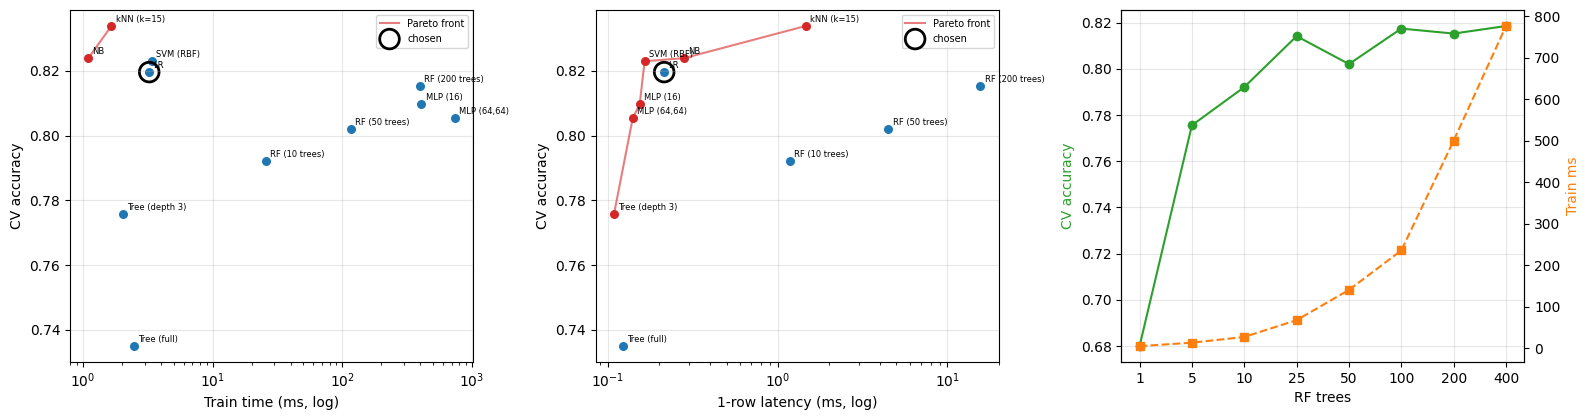

 trees  accuracy  train ms
     1     0.680       5.3
     5     0.776      13.6
    10     0.792      27.4
    25     0.814      67.9
    50     0.802     140.7
   100     0.817     235.8
   200     0.815     500.5
   400     0.819     776.6


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, c, xl in [(axes[0], tt, 'Train time (ms, log)'), (axes[1], lat, '1-row latency (ms, log)')]:
    front = sorted(pareto(c), key=lambda n: c[n])
    ax.plot([c[n] for n in front], [acc[n] for n in front], '-', color='tab:red', alpha=0.6, label='Pareto front')
    for n in names: ax.scatter(c[n], acc[n], color='tab:red' if n in front else 'tab:blue', s=30); ax.annotate(n, (c[n], acc[n]), fontsize=6, xytext=(3, 3), textcoords='offset points')
    ax.scatter(c[choice], acc[choice], s=200, facecolors='none', edgecolors='k', linewidths=2, label='chosen')
    ax.set_xscale('log'); ax.set_xlabel(xl); ax.set_ylabel('CV accuracy'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
trees = [1, 5, 10, 25, 50, 100, 200, 400]; sw_acc, sw_t = [], []
for nt in trees:
    a, f = [], []
    for rep in range(3):
        folds = make_folds(len(X), 5, rep)
        for k in range(5):
            te = folds[k]; tr = np.concatenate([folds[i] for i in range(5) if i != k]); m_, s_ = X[tr].mean(0), X[tr].std(0)
            m, ms = timed(lambda: RandomForestClassifier(nt, random_state=0).fit((X[tr] - m_) / s_, y[tr])); f.append(ms); a.append(np.mean(m.predict((X[te] - m_) / s_) == y[te]))
    sw_acc.append(np.mean(a)); sw_t.append(np.mean(f))
axes[2].plot(range(len(trees)), sw_acc, 'o-', color='tab:green'); axes[2].set_ylabel('CV accuracy', color='tab:green'); axes[2].set_xticks(range(len(trees))); axes[2].set_xticklabels(trees); axes[2].set_xlabel('RF trees')
ax2 = axes[2].twinx(); ax2.plot(range(len(trees)), sw_t, 's--', color='tab:orange'); ax2.set_ylabel('Train ms', color='tab:orange'); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(pd.DataFrame({'trees': trees, 'accuracy': np.round(sw_acc, 3), 'train ms': np.round(sw_t, 1)}).to_string(index=False))

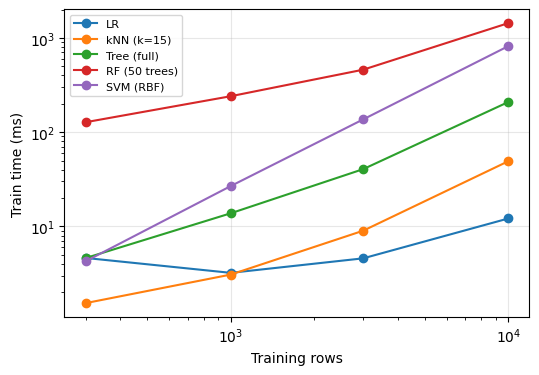

         LR  kNN (k=15)  Tree (full)  RF (50 trees)  SVM (RBF)
300     4.6         1.5          4.6          127.5        4.3
1000    3.2         3.1         13.8          240.6       26.8
3000    4.6         9.0         40.5          459.9      136.6
10000  12.2        49.2        208.8         1434.1      817.5


In [17]:
sizes = [300, 1000, 3000, 10000]; pick = ['LR', 'kNN (k=15)', 'Tree (full)', 'RF (50 trees)', 'SVM (RBF)']
rng = np.random.default_rng(0); scal = {n: [] for n in pick}
for s in sizes:
    i = rng.integers(0, len(Xs), s); A = Xs[i] + rng.normal(0, 0.1, (s, Xs.shape[1])); t = y[i]
    for n in pick: scal[n].append(min(timed(lambda: models[n]().fit(A, t))[1] for _ in range(2)))
plt.figure(figsize=(6, 4))
for n in pick: plt.plot(sizes, scal[n], 'o-', label=n)
plt.xscale('log'); plt.yscale('log'); plt.xlabel('Training rows'); plt.ylabel('Train time (ms)'); plt.legend(fontsize=8); plt.grid(alpha=0.3)
plt.show()
print(pd.DataFrame(scal, index=sizes).round(1).to_string())